In [27]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import pickle

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_worm import artificializer
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import trainer
from models import bom
from models import hgm


# jax.config.update("jax_enable_x64", True)

In [28]:
import importlib
importlib.reload(artificializer)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(trainer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [29]:
manual_hyperparameters = {
	# 'max_epochs': 3000,
	'max_epochs': 3000,
	'max_patience': 3000 / 4,
	'learning_rate': 1E-0,
	'dimensions': 2,
	'ccadiag_lambda': 0.6,
	'ccaunit_lambda': 1.0 - 0.6,
	'loss_man_lambda': 0.0,
	'loss_res_lambda': 1.0 - 0.0,
	'wb_reg_lambda': 1E-3,
	'wm_reg_lambda': 1E-6,
}

# Functions

In [30]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [31]:
def train_model(model, splits, N, B, S, hyperparams=None):
	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3), jax.random.PRNGKey(4)

	global manual_hyperparameters
	hyperparameters = manual_hyperparameters.copy()
	if hyperparams is not None:
		for key in hyperparams:
			hyperparameters[key] = hyperparams[key]

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	n_dimensions = hyperparameters['dimensions']

	lambdas = Lambdas(
		loss_lambdas=(hyperparameters['loss_man_lambda'], hyperparameters['loss_res_lambda']),
		reg_lambdas=(hyperparameters['wb_reg_lambda'], hyperparameters['wm_reg_lambda']),
		cca_lambdas=(hyperparameters['ccadiag_lambda'], hyperparameters['ccaunit_lambda'])
	)
	#endregion ===========================================================================

	n_neurons = N.shape[1]
	n_states = S.shape[1]
	n_behaviors = B.shape[1]

	N, B, S = jnp.asarray(N), jnp.asarray(B), jnp.asarray(S)

	# training loop ==============================
	params_per_split = list()
	(losses_train_per_split,
	 man_losses_train_per_split,
	 res_losses_train_per_split,
	 mpe_losses_train_per_split) = list(), list(), list(), list()
	(losses_per_split,
	 man_losses_per_split,
	 res_losses_per_split,
	 mpe_losses_per_split) = list(), list(), list(), list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		N_train, N_eval = N[train], N[eval]
		B_train, B_eval = B[train], B[eval]
		S_train, S_eval = S[train], S[eval]

		params = model.init_params(N_train, B_train, S_train,
								   seeds,
								   (n_neurons, n_dimensions),
								   (n_states, n_dimensions),
								   (n_behaviors, n_neurons),
								   * ((n_dimensions, n_neurons),) if model.get_type() else (),
								  )

		optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(init_value=learning_rate, decay_steps=max_epochs, alpha=1E-4))
		# optimizer = optax.adam(learning_rate=learning_rate)
		optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		# train the split
		(params,
		 losses_train, man_losses_train, res_losses_train, mpe_losses_train,
		 losses, man_losses, res_losses, mpe_losses, epoch_end
		 ) = trainer.train(lambdas,
						   max_epochs, max_patience,
						   model, optimizer.update,
						   opt_state, params,
						   N_train, B_train, S_train,
						   N_eval,  B_eval,  S_eval,)

		# save the split
		params_per_split.append(jax.device_get(params))

		losses_train_per_split.append(jax.device_get(losses_train))
		man_losses_train_per_split.append(jax.device_get(man_losses_train))
		res_losses_train_per_split.append(jax.device_get(res_losses_train))
		mpe_losses_train_per_split.append(jax.device_get(mpe_losses_train))

		losses_per_split.append(jax.device_get(losses))
		man_losses_per_split.append(jax.device_get(man_losses))
		res_losses_per_split.append(jax.device_get(res_losses))
		mpe_losses_per_split.append(jax.device_get(mpe_losses))

		# log
		print(f'{f'Stopped after {epoch_end} epochs: ' if epoch_end < max_epochs else ''}Split {s_id} completed. ', end='')

	# ============================================

	# return
	return (params_per_split,
			np.stack(losses_train_per_split),
			np.stack(man_losses_train_per_split),
			np.stack(res_losses_train_per_split),
			np.stack(mpe_losses_train_per_split),
			np.stack(losses_per_split),
			np.stack(man_losses_per_split),
			np.stack(res_losses_per_split),
			np.stack(mpe_losses_per_split))

In [32]:
def train_models(model, filenames, discrete_states, eigenworms, traces, hyperparams=None, save_name=None):
	models_params = list()
	models_losses, models_man_losses, models_res_losses, models_mpe_losses = list(), list(), list(), list()
	models_losses_train, models_man_losses_train, models_res_losses_train, models_mpe_losses_train = list(), list(), list(), list()

	for i in range(len(filenames)):
		print(f'\n{i+1}/{len(filenames)}: {filenames[i]}... ', end='')

		splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces[i].shape[0]), discrete_states[i][['REV']].values))

		(params_per_split,
		 losses_train_per_split, man_losses_train_per_split, res_losses_train_per_split, mpe_losses_train_per_split,
		 losses_per_split, man_losses_per_split, res_losses_per_split, mpe_losses_per_split
		 ) = train_model(model, splits,
						 traces[i].values,
						 eigenworms[i].values,
						 discrete_states[i].values,
						 hyperparams)

		models_params.append(params_per_split)

		models_losses_train.append(losses_train_per_split)
		models_man_losses_train.append(man_losses_train_per_split)
		models_res_losses_train.append(res_losses_train_per_split)
		models_mpe_losses_train.append(mpe_losses_train_per_split)

		models_losses.append(losses_per_split)
		models_man_losses.append(man_losses_per_split)
		models_res_losses.append(res_losses_per_split)
		models_mpe_losses.append(mpe_losses_per_split)

	if save_name is not None:
		train_utils.save_params(filenames, models_params, save_name)
		train_utils.save_losses(filenames, [
			np.array([models_losses_train[i], models_man_losses_train[i], models_res_losses_train[i], models_mpe_losses_train[i],
					  models_losses[i], models_man_losses[i], models_res_losses[i], models_mpe_losses[i]]) for i in range(len(filenames))
		], save_name)

	return (models_params,
			models_losses_train, models_man_losses_train, models_res_losses_train, models_mpe_losses_train,
			models_losses, models_man_losses, models_res_losses, models_mpe_losses)

# read & prep

In [33]:
ll = f'll{int(manual_hyperparameters['loss_man_lambda'] * 100):02d}'

with open('../sweep/hyperparams.pkl', 'rb') as f:
	swept_hyperparameters = pickle.load(f)

bom_reg_lambdas = {
	# 'wb_reg_lambda': manual_hyperparameters['wb_reg_lambda'],
	'wb_reg_lambda': swept_hyperparameters[ll]['bom_ns']['means']['wb_reg_lambda']['geometric'],
}
hgm_reg_lambdas = {
	# 'wb_reg_lambda': manual_hyperparameters['wb_reg_lambda'],
	'wb_reg_lambda': swept_hyperparameters[ll]['hgm_ns']['means']['wb_reg_lambda']['geometric'],
	# 'wm_reg_lambda': manual_hyperparameters['wm_reg_lambda'],
	'wm_reg_lambda': swept_hyperparameters[ll]['hgm_ns']['means']['wm_reg_lambda']['geometric'],
}

In [34]:
artificial = True
if artificial:
	dims_generation = 2
	weights = (0.1, -0.25)


gcamp = True
file_ids_gcamp = list(range(0, 33+1))
# file_ids_gcamp = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
# file_ids_gcamp = [19]
plot_id_gcamp = 19


gfp = True
if gfp:
	file_ids_gfp = list(range(0, 7+1))
	# file_ids_gfp = [2, 4, 6]
	# file_ids_gfp = [2]
	plot_id_gfp = 2

In [35]:
# read

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_datas(path, file_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	path = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_datas(path, file_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])

In [36]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

plot_idx_gcamp = file_ids_gcamp.index(plot_id_gcamp)
selection_n_gcamp = [label for label in selection_n if label in traces_gcamp[plot_idx_gcamp].columns]

if gfp:
	plot_idx_gfp = file_ids_gfp.index(plot_id_gfp)
	selection_n_gfp = [label for label in selection_n if label in traces_gfp[plot_idx_gfp].columns]

# discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

In [37]:
# generate

if artificial:
	plot_id_art = plot_id_gfp

	file_ids_art = list()
	filenames_art = list()

	discrete_states_art = list()
	eigenworms_art = list()

	modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()

	for i in range(len(file_ids_gfp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gfp[i],
														 traces_gfp[i].columns,
														 eigenworms_gfp[i],
														 [ds[selection_bhl] for ds in discrete_states_gfp][i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)

		modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

		file_ids_art.append(file_ids_gfp[i])

		discrete_states_art.append(discrete_states_gfp[i].copy())
		eigenworms_art.append(eigenworms_gfp[i].copy())

	plot_idx_art = file_ids_art.index(plot_id_art)

# ARTIFICIAL

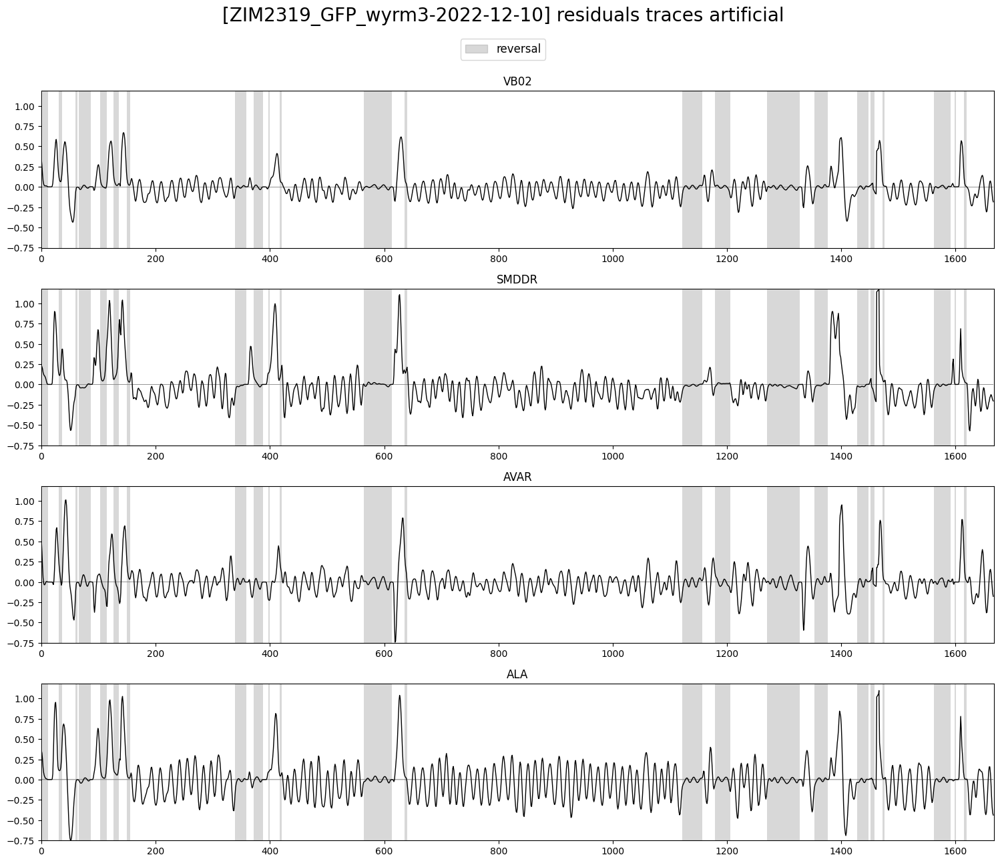

In [38]:
if artificial:
	plot_utils.plot_traces(traces_residual_art[plot_idx_art][selection_n_gfp],
						   discrete_states_art[plot_idx_art][['REV']],
						   label='reversal',
						   title=f'[{filenames_art[plot_idx_art]}] residuals traces artificial', ylimits=0.05)

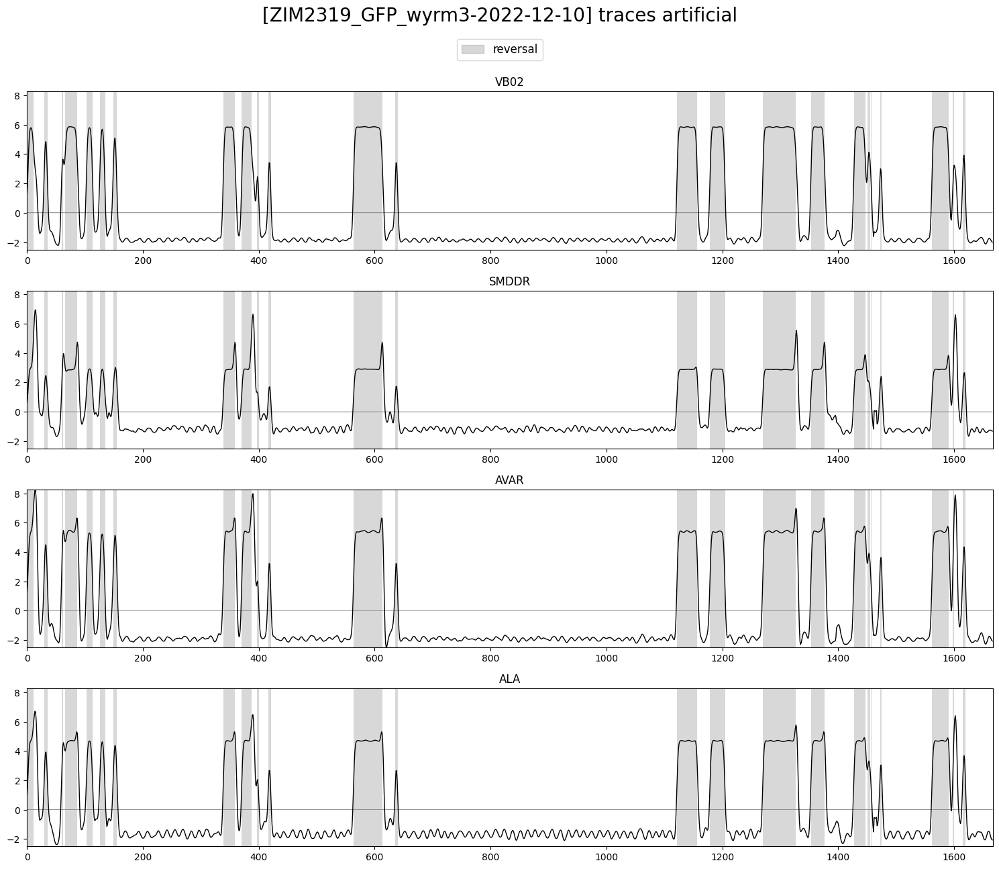

In [39]:
if artificial:
	plot_utils.plot_traces(traces_art[plot_idx_art][selection_n_gfp],
						   discrete_states_art[plot_idx_art][['REV']],
						   label='reversal',
						   title=f'[{filenames_art[plot_idx_art]}] traces artificial', ylimits=0.05)

### BOM

In [40]:
if artificial:
	(boms_params_art,
	 boms_losses_train_art, boms_man_losses_train_art, boms_res_losses_train_art, boms_mpe_losses_train_art,
	 boms_losses_test_art, boms_man_losses_test_art, boms_res_losses_test_art, boms_mpe_losses_test_art
	 ) = train_models(bom,
					  filenames_art,
					  discrete_states_art,
					  eigenworms_art,
					  traces_art,
					  hyperparams=bom_reg_lambdas,
					  save_name=os.path.join('worm-2025-fieseler', 'new', ll, f'ns_bom_art_wb-{bom_reg_lambdas['wb_reg_lambda']:.2E}'))  #save_name=None


1/8: ZIM2319_GFP_wyrm1-2022-12-10... Stopped after 2777 epochs: Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
2/8: ZIM2319_GFP_wyrm2-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
3/8: ZIM2319_GFP_wyrm3-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
4/8: ZIM2319_GFP_wyrm4-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
5/8: ZIM2319_GFP_wyrm5-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
6/8: ZIM2319_GFP_wyrm6-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
7/8: ZIM2319_GFP_wyrm7-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
8/8: ZIM2319_GFP_wyrm8-2022-12-10... Spli

### HGM

In [41]:
if artificial:
	(hgms_params_art,
	 hgms_losses_train_art, hgms_man_losses_train_art, hgms_res_losses_train_art, hgms_mpe_losses_train_art,
	 hgms_losses_test_art, hgms_man_losses_test_art, hgms_res_losses_test_art, hgms_mpe_losses_test_art,
	 ) = train_models(hgm,
					  filenames_art,
					  discrete_states_art,
					  eigenworms_art,
					  traces_art,
					  hyperparams=hgm_reg_lambdas,
					  save_name=os.path.join('worm-2025-fieseler', 'new', ll, f'ns_hgm_art_wb-{hgm_reg_lambdas['wb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}'))  #save_name=None


1/8: ZIM2319_GFP_wyrm1-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
2/8: ZIM2319_GFP_wyrm2-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 2758 epochs: Split 4 completed. 
3/8: ZIM2319_GFP_wyrm3-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
4/8: ZIM2319_GFP_wyrm4-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
5/8: ZIM2319_GFP_wyrm5-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
6/8: ZIM2319_GFP_wyrm6-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
7/8: ZIM2319_GFP_wyrm7-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
8/8: ZIM2319_GFP_wyrm8-2022-12-10... Spli

## losses

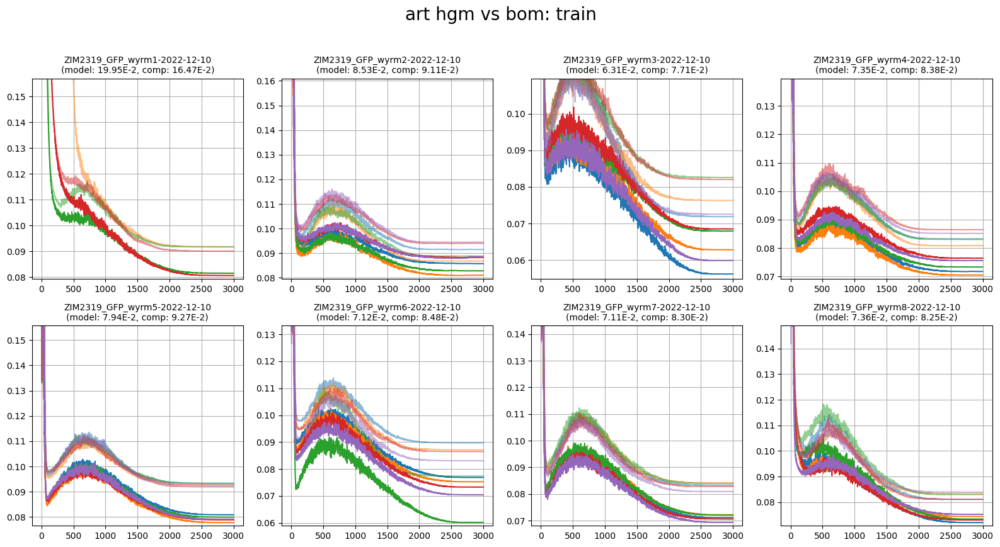

In [75]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_losses_train_art, boms_losses_train_art,
								  title='art hgm vs bom: train',
								  ylimits=0.0125)

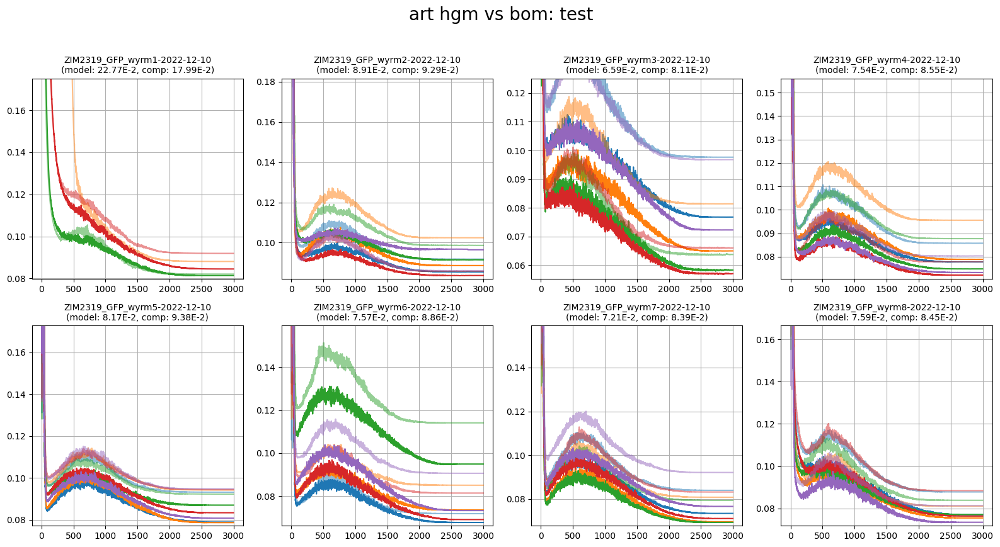

In [77]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_losses_test_art, boms_losses_test_art,
								  title='art hgm vs bom: test',
								  ylimits=0.015)

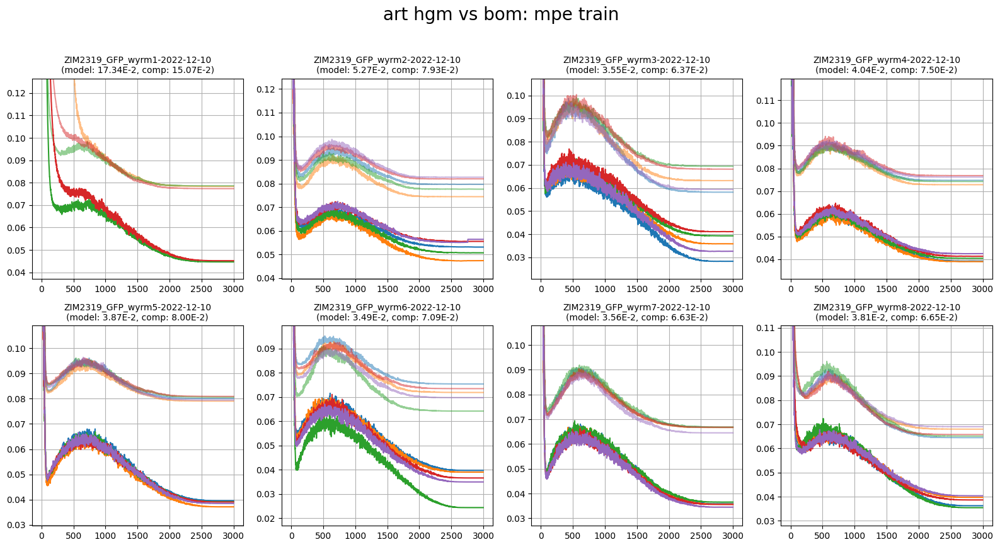

In [80]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_mpe_losses_train_art, boms_mpe_losses_train_art,
								  title='art hgm vs bom: mpe train',
								  ylimits=0.075)

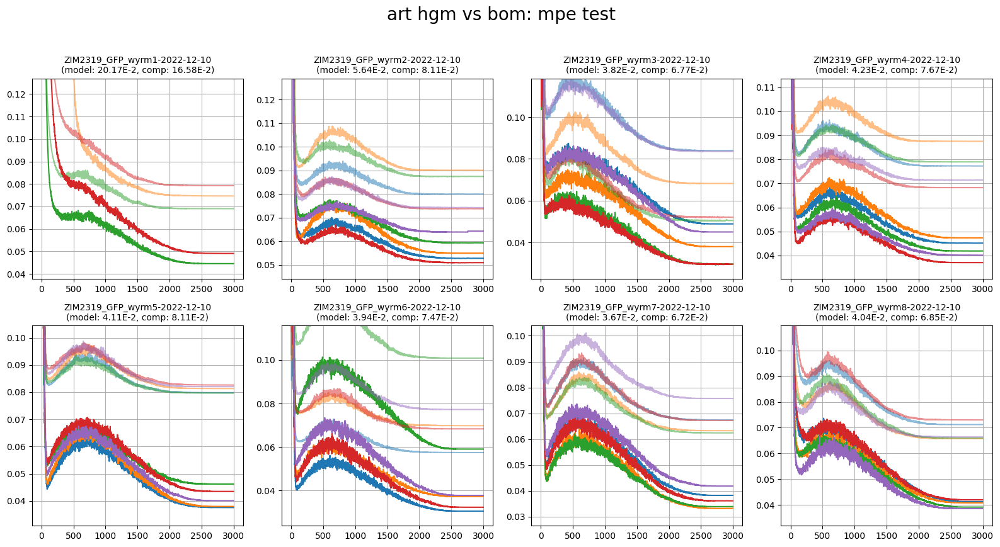

In [81]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_mpe_losses_test_art, boms_mpe_losses_test_art,
								  title='art hgm vs bom: mpe test',
								  ylimits=0.067)

# GCAMP

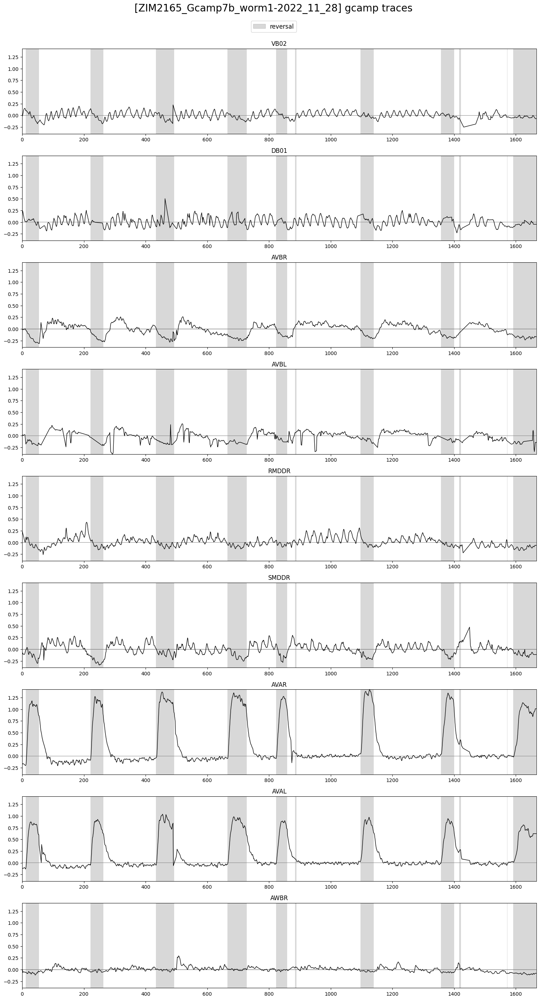

In [46]:
if gcamp:
	plot_utils.plot_traces(traces_gcamp[plot_idx_gcamp][selection_n_gcamp],
						   discrete_states_gcamp[plot_idx_gcamp][['REV']],
						   label='reversal',
						   title=f'[{filenames_gcamp[plot_idx_gcamp]}] gcamp traces', ylimits=0.05)

### BOM

In [47]:
if gcamp:
	(boms_params_gcamp,
	 boms_losses_train_gcamp, boms_man_losses_train_gcamp, boms_res_losses_train_gcamp, boms_mpe_losses_train_gcamp,
	 boms_losses_test_gcamp, boms_man_losses_test_gcamp, boms_res_losses_test_gcamp, boms_mpe_losses_test_gcamp,
	 ) = train_models(bom,
					  filenames_gcamp,
					  discrete_states_gcamp,
					  eigenworms_gcamp,
					  traces_gcamp,
					  hyperparams=bom_reg_lambdas,
					  save_name=os.path.join('worm-2025-fieseler', 'new', ll, f'ns_bom_gcamp_wb-{bom_reg_lambdas['wb_reg_lambda']:.2E}'))  #save_name=None


1/34: 2022-11-23_worm10... Stopped after 2998 epochs: Split 0 completed. Stopped after 2915 epochs: Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
2/34: 2022-11-23_worm11... Stopped after 2995 epochs: Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 2917 epochs: Split 4 completed. 
3/34: 2022-11-23_worm12... Split 0 completed. Stopped after 2957 epochs: Split 1 completed. Split 2 completed. Stopped after 2899 epochs: Split 3 completed. Split 4 completed. 
4/34: 2022-11-23_worm8... Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 2897 epochs: Split 3 completed. Split 4 completed. 
5/34: 2022-11-23_worm9... Split 0 completed. Split 1 completed. Stopped after 2895 epochs: Split 2 completed. Stopped after 2924 epochs: Split 3 completed. Split 4 completed. 
6/34: 2023-11-21_12-39_wt_worm1-2023-11-21... Split 0 completed. Split 1 completed. Stopped after 2930 epochs: Split 2 completed. Stopped after

### HGM

In [48]:
if gcamp:
	(hgms_params_gcamp,
	 hgms_losses_train_gcamp, hgms_man_losses_train_gcamp, hgms_res_losses_train_gcamp, hgms_mpe_losses_train_gcamp,
	 hgms_losses_test_gcamp, hgms_man_losses_test_gcamp, hgms_res_losses_test_gcamp, hgms_mpe_losses_test_gcamp,
	 ) = train_models(hgm,
					  filenames_gcamp,
					  discrete_states_gcamp,
					  eigenworms_gcamp,
					  traces_gcamp,
					  hyperparams=hgm_reg_lambdas,
					  save_name=os.path.join('worm-2025-fieseler', 'new', ll, f'ns_hgm_gcamp_wb-{hgm_reg_lambdas['wb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}'))  #save_name=None


1/34: 2022-11-23_worm10... Stopped after 2799 epochs: Split 0 completed. Split 1 completed. Stopped after 2962 epochs: Split 2 completed. Split 3 completed. Split 4 completed. 
2/34: 2022-11-23_worm11... Split 0 completed. Stopped after 2787 epochs: Split 1 completed. Split 2 completed. Stopped after 2970 epochs: Split 3 completed. Stopped after 2844 epochs: Split 4 completed. 
3/34: 2022-11-23_worm12... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 2942 epochs: Split 4 completed. 
4/34: 2022-11-23_worm8... Split 0 completed. Stopped after 2681 epochs: Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 2872 epochs: Split 4 completed. 
5/34: 2022-11-23_worm9... Split 0 completed. Split 1 completed. Stopped after 2821 epochs: Split 2 completed. Split 3 completed. Split 4 completed. 
6/34: 2023-11-21_12-39_wt_worm1-2023-11-21... Stopped after 2625 epochs: Split 0 completed. Stopped after 2682 epochs: Split 1 completed. Split

### losses

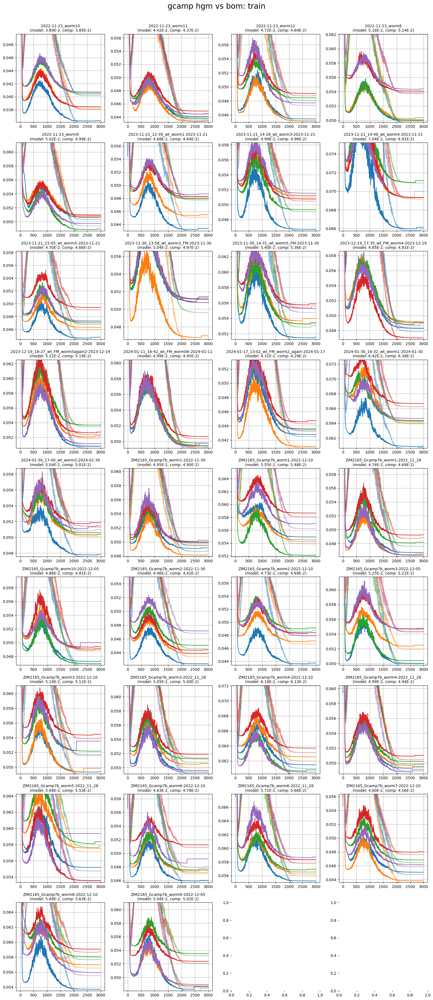

In [85]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_losses_train_gcamp, boms_losses_train_gcamp,
								  title='gcamp hgm vs bom: train',
								  ylimits=0.002)

In [87]:
# if gcamp:
# 	plot_utils.plot_losses_splits(filenames_gcamp,
# 								  hgms_man_losses_train_gcamp, boms_man_losses_train_gcamp,
# 								  title='gcamp hgm vs bom: man train',
# 								  ylimits=None)

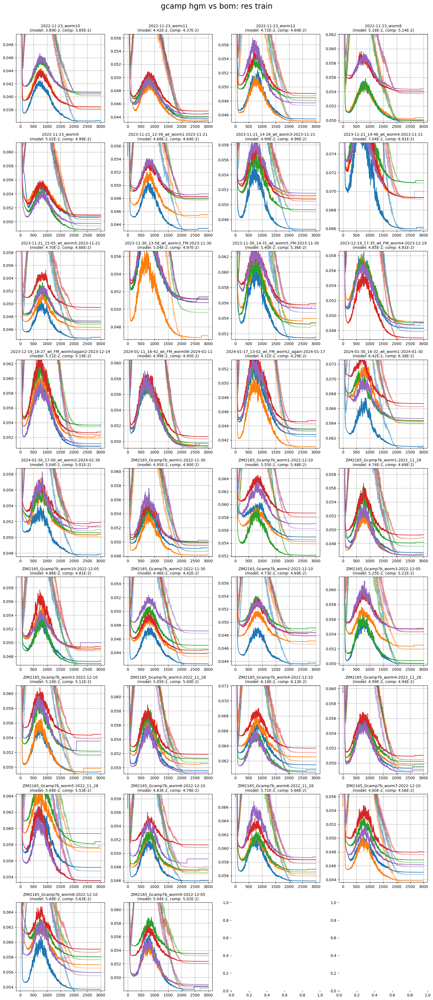

In [89]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_res_losses_train_gcamp, boms_res_losses_train_gcamp,
								  title='gcamp hgm vs bom: res train',
								  ylimits=0.002)

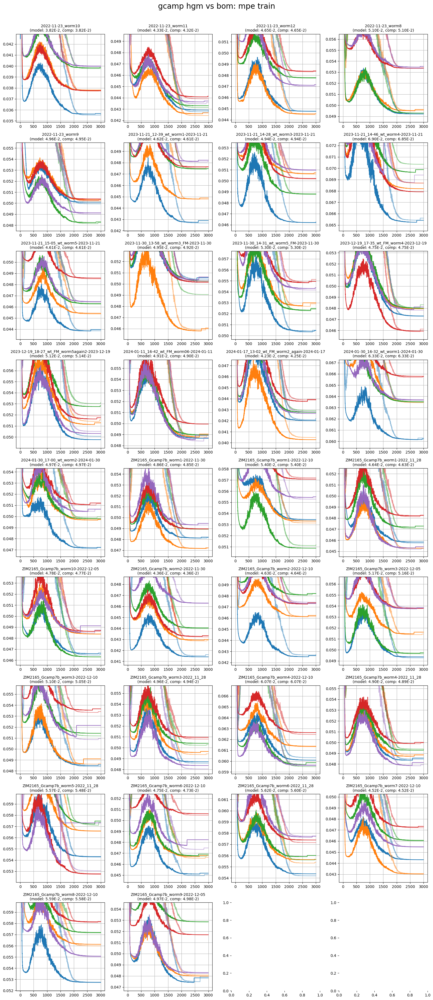

In [92]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
								  title='gcamp hgm vs bom: mpe train',
								  ylimits=0.0075)

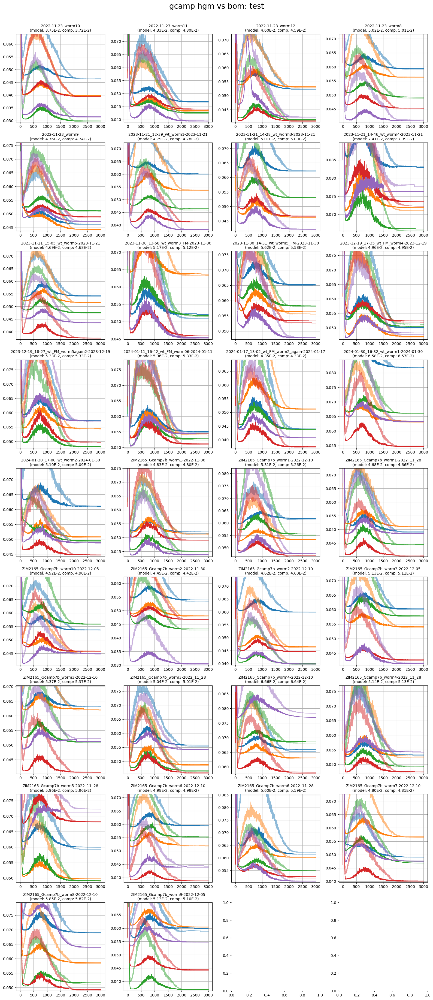

In [94]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_losses_test_gcamp, boms_losses_test_gcamp,
								  title='gcamp hgm vs bom: test',
								  ylimits=0.005)

In [95]:
# if gcamp:
# 	plot_utils.plot_losses_splits(filenames_gcamp,
# 								  hgms_man_losses_test_gcamp, boms_man_losses_test_gcamp,
# 								  title='gcamp hgm vs bom: man test',
# 								  ylimits=None)

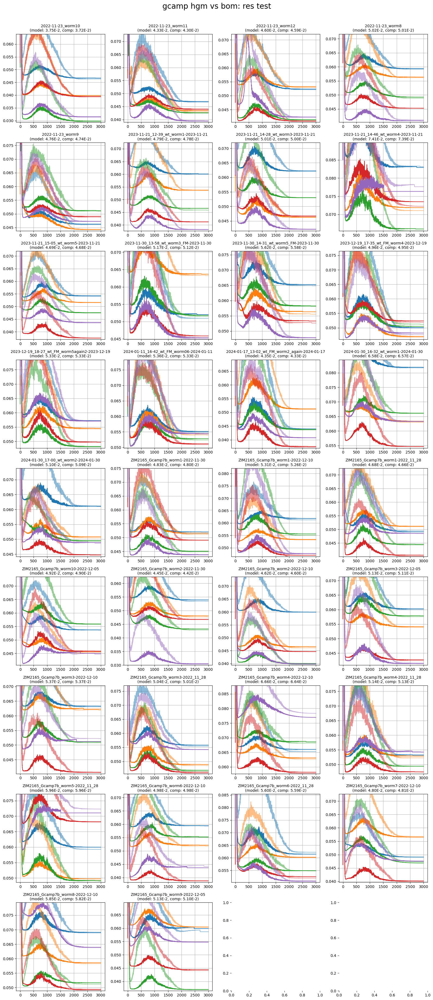

In [98]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_res_losses_test_gcamp, boms_res_losses_test_gcamp,
								  title='gcamp hgm vs bom: res test',
								  ylimits=0.005)

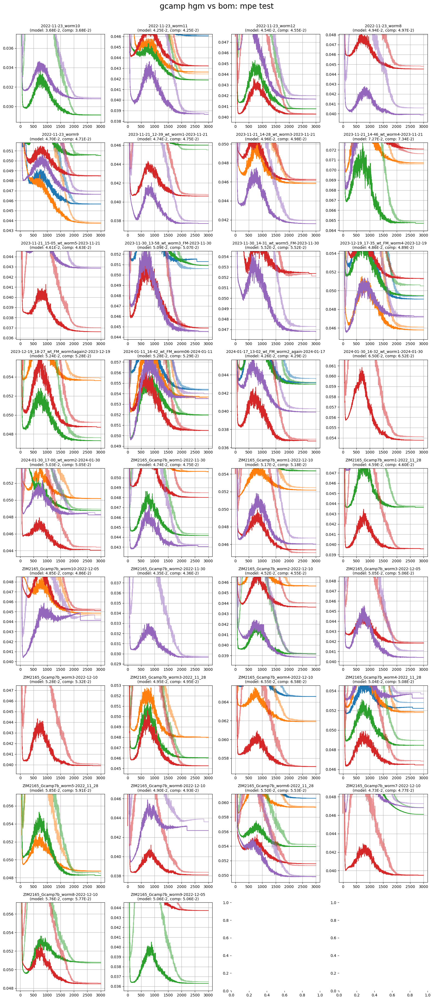

In [100]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_mpe_losses_test_gcamp, boms_mpe_losses_test_gcamp,
								  title='gcamp hgm vs bom: mpe test',
								  ylimits=0.0075)

# GFP

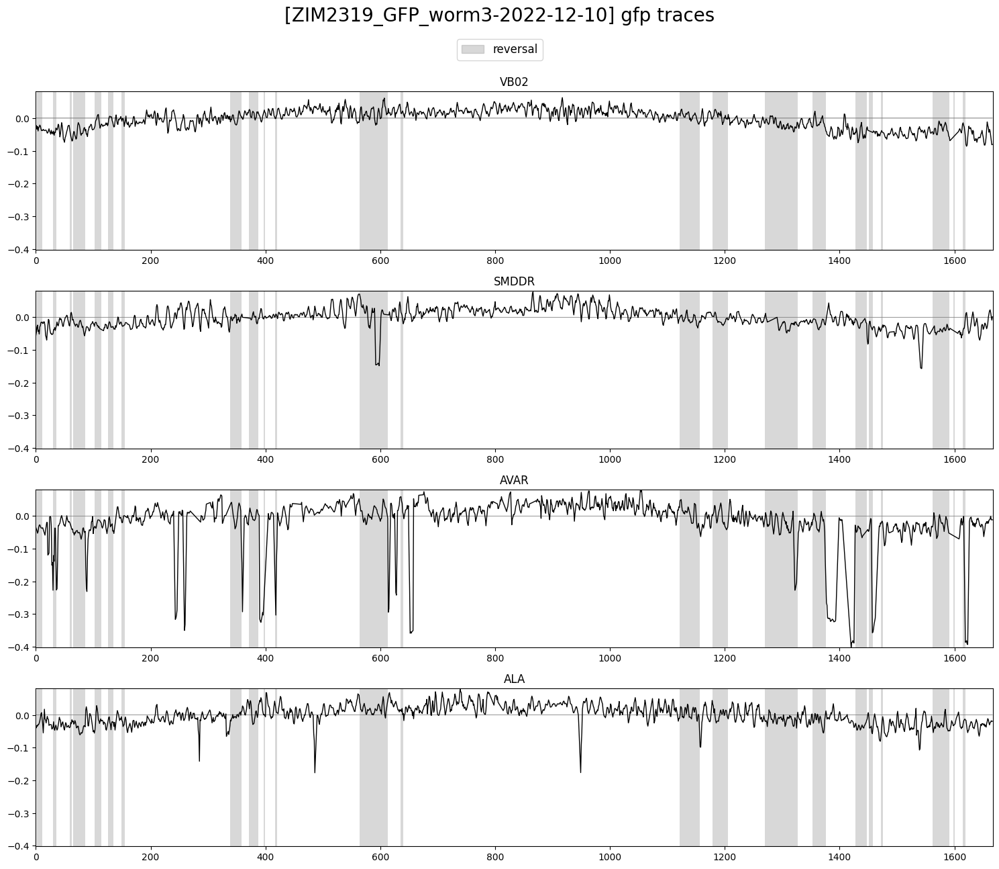

In [57]:
if gfp:
	plot_utils.plot_traces(traces_gfp[plot_idx_gfp][selection_n_gfp],
						   discrete_states_gfp[plot_idx_gfp][['REV']],
						   label='reversal',
						   title=f'[{filenames_gfp[plot_idx_gfp]}] gfp traces', ylimits=0.05)

### BOM

In [58]:
if gfp:
	(boms_params_gfp,
	 boms_losses_train_gfp, boms_man_losses_train_gfp, boms_res_losses_train_gfp, boms_mpe_losses_train_gfp,
	 boms_losses_test_gfp, boms_man_losses_test_gfp, boms_res_losses_test_gfp, boms_mpe_losses_test_gfp,
	 ) = train_models(bom,
					  filenames_gfp,
					  discrete_states_gfp,
					  eigenworms_gfp,
					  traces_gfp,
					  hyperparams=bom_reg_lambdas,
					  save_name=os.path.join('worm-2025-fieseler', 'new', ll, f'ns_bom_gfp_wb-{bom_reg_lambdas['wb_reg_lambda']:.2E}'))  #save_name=None


1/8: ZIM2319_GFP_worm1-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
2/8: ZIM2319_GFP_worm2-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
3/8: ZIM2319_GFP_worm3-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
4/8: ZIM2319_GFP_worm4-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
5/8: ZIM2319_GFP_worm5-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
6/8: ZIM2319_GFP_worm6-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
7/8: ZIM2319_GFP_worm7-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
8/8: ZIM2319_GFP_worm8-2022-12-10... Split 0 completed. Split 1 comp

### HGM

In [59]:
if gfp:
	(hgms_params_gfp,
	 hgms_losses_train_gfp, hgms_man_losses_train_gfp, hgms_res_losses_train_gfp, hgms_mpe_losses_train_gfp,
	 hgms_losses_test_gfp, hgms_man_losses_test_gfp, hgms_res_losses_test_gfp, hgms_mpe_losses_test_gfp,
	 ) = train_models(hgm,
					  filenames_gfp,
					  discrete_states_gfp,
					  eigenworms_gfp,
					  traces_gfp,
					  hyperparams=hgm_reg_lambdas,
					  save_name=os.path.join('worm-2025-fieseler', 'new', ll, f'ns_hgm_gfp_wb-{hgm_reg_lambdas['wb_reg_lambda']:.2E}_wm-{hgm_reg_lambdas['wm_reg_lambda']:.2E}'))  #save_name=None


1/8: ZIM2319_GFP_worm1-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
2/8: ZIM2319_GFP_worm2-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Stopped after 2970 epochs: Split 3 completed. Stopped after 2970 epochs: Split 4 completed. 
3/8: ZIM2319_GFP_worm3-2022-12-10... Stopped after 2994 epochs: Split 0 completed. Stopped after 2968 epochs: Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
4/8: ZIM2319_GFP_worm4-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
5/8: ZIM2319_GFP_worm5-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
6/8: ZIM2319_GFP_worm6-2022-12-10... Stopped after 2906 epochs: Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
7/8: ZIM2319_GFP_worm7-2022-12-10... Split 0 completed. Stopped af

### losses

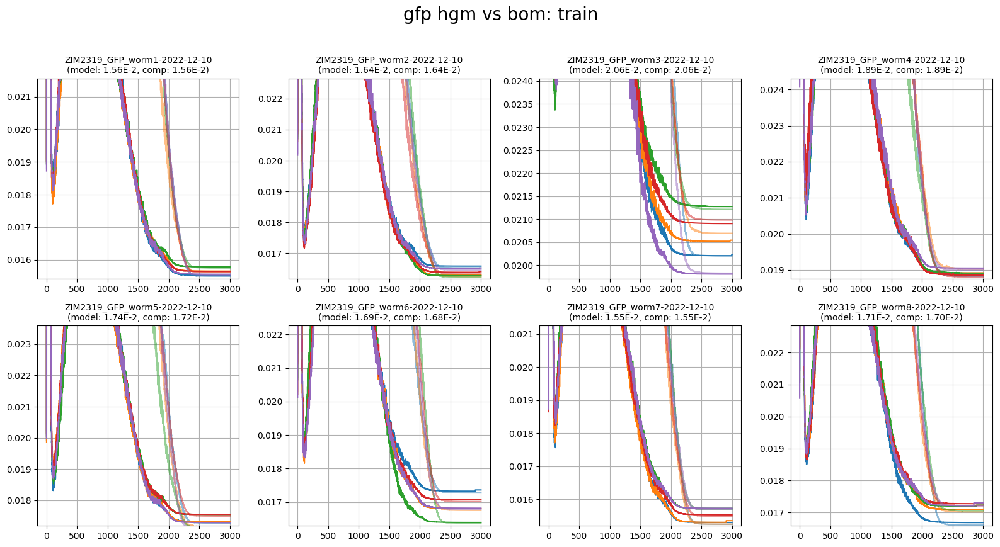

In [104]:
if gfp:
	plot_utils.plot_losses_splits(filenames_gfp,
								  hgms_losses_train_gfp, boms_losses_train_gfp,
								  title='gfp hgm vs bom: train',
								  ylimits=0.001)

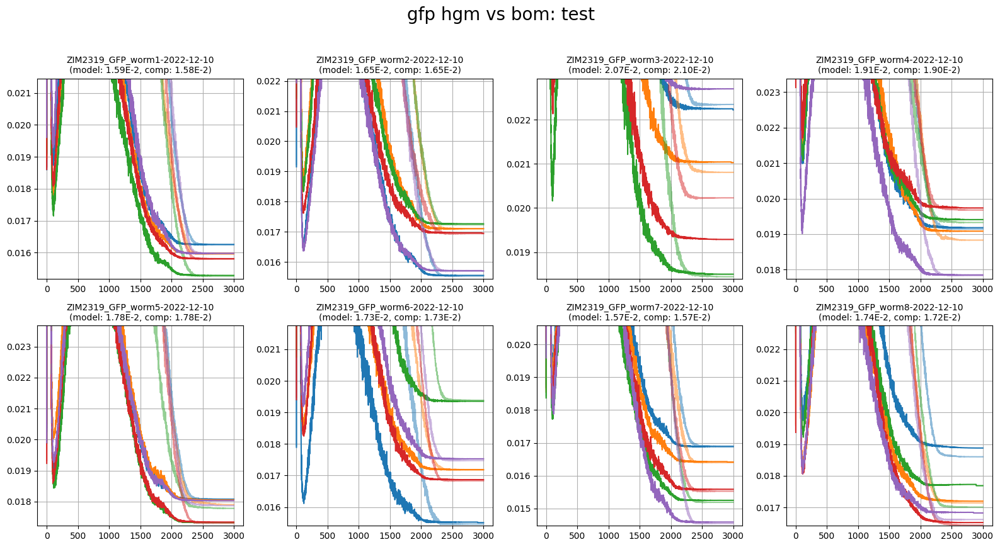

In [105]:
if gfp:
	plot_utils.plot_losses_splits(filenames_gfp,
								  hgms_losses_test_gfp, boms_losses_test_gfp,
								  title='gfp hgm vs bom: test',
								  ylimits=0.001)

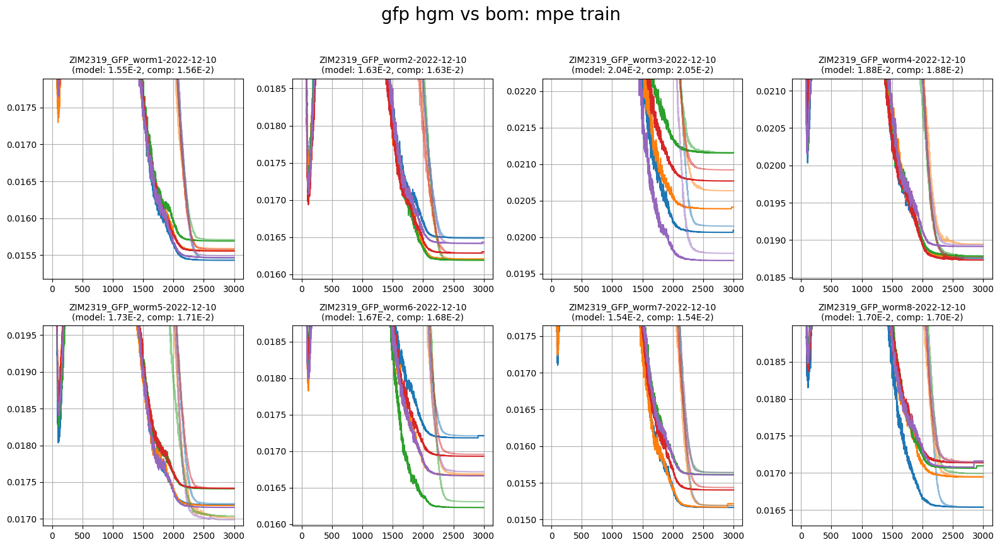

In [110]:
if gfp:
	plot_utils.plot_losses_splits(filenames_gfp,
								  hgms_mpe_losses_train_gfp, boms_mpe_losses_train_gfp,
								  title='gfp hgm vs bom: mpe train',
								  ylimits=0.0025)

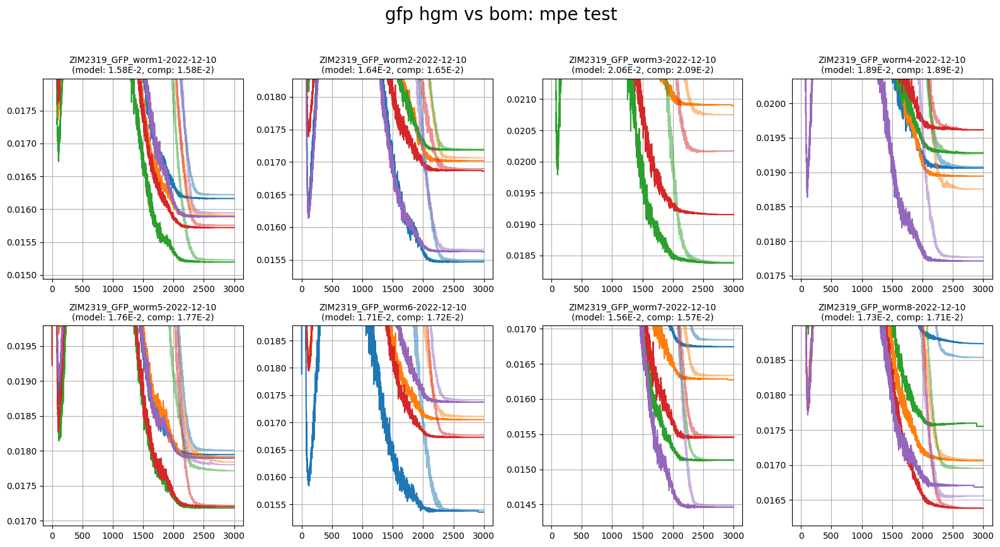

In [109]:
if gfp:
	plot_utils.plot_losses_splits(filenames_gfp,
								  hgms_mpe_losses_test_gfp, boms_mpe_losses_test_gfp,
								  title='gfp hgm vs bom: mpe test',
								  ylimits=0.0025)